# Прогноз покупки в интернет-магазине

Цель работы — предсказать, завершится ли посещение сайта покупкой.
Целевая переменная — Revenue: True означает покупку, False — её отсутствие.

План: проверить данные, провести EDA, подготовить признаки,
сравнить модели и проверить гипотезы, сформулированные в README.

In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)

## 1. Загрузка и проверка данных

Посмотрим на размер таблицы, примеры строк, типы столбцов,
пропуски и полностью совпадающие строки.

In [28]:
data_path = Path("data/online_shoppers_intention.csv")
df = pd.read_csv(data_path)

print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

df.head()

Количество строк: 12330
Количество столбцов: 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [30]:
data_check = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})

display(data_check)

print("Полностью совпадающих строк:", df.duplicated().sum())
print("Значения целевой переменной:", df["Revenue"].unique())

,dtype,missing,unique
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


Полностью совпадающих строк: 125
Значения целевой переменной: [False  True]


### Первичная проверка

В датасете 12 330 строк и 18 столбцов, включая целевую
переменную Revenue. Пропусков нет. Найдено 125 полностью
совпадающих строк; пока оставим их, так как они могут
соответствовать разным посещениям.

Часть категориальных признаков записана числами, например
Browser и Region. При подготовке данных их нужно обрабатывать
как категории.

## 2. Разделение данных

Отделим 20% данных для итоговой проверки. Используем
стратификацию, чтобы доли классов в обеих частях были похожи.

In [31]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Revenue")
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (9864, 17)
Тестовая выборка: (2466, 17)


## 3. Исследовательский анализ данных (EDA)

### Распределение целевой переменной

Посмотрим, какая доля посещений завершилась покупкой.

In [32]:
class_counts = y_train.value_counts().sort_index()
class_percentages = y_train.value_counts(normalize=True).sort_index() * 100

class_distribution = pd.DataFrame({
    "Количество": class_counts,
    "Доля, %": class_percentages.round(2),
})

display(class_distribution)

,Количество,"Доля, %"
Revenue,,
False,8338,84.53
True,1526,15.47


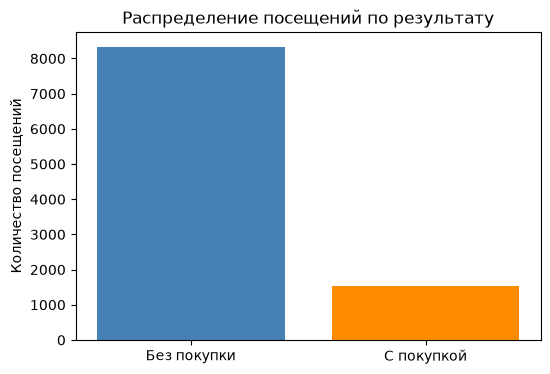

In [33]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    ["Без покупки", "С покупкой"],
    class_counts.values,
    color=["steelblue", "darkorange"],
)

ax.set_title("Распределение посещений по результату")
ax.set_ylabel("Количество посещений")

plt.show()

Большинство посещений в обучающей выборке (84,53%) не
заканчивается покупкой. Из-за дисбаланса классов одной accuracy
недостаточно: модель может получить высокое значение, всегда
предсказывая отсутствие покупки.

Для оценки класса покупки дополнительно будем использовать
precision, recall и F1.

### Распределения числовых признаков

Изучим количество просмотренных страниц и время, проведённое
на страницах товаров.

In [34]:
numeric_columns = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "ProductRelated_Duration",
]

X_train[numeric_columns].describe().round(2)

,Administrative,Informational,ProductRelated,ProductRelated_Duration
count,9864.00,9864.00,9864.00,9864.00
mean,2.32,0.50,31.45,1186.55
std,3.32,1.28,43.62,1909.25
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,7.00,182.57
50%,1.00,0.00,18.00,600.54
75%,4.00,0.00,38.00,1474.51
max,27.00,24.00,705.00,63973.52


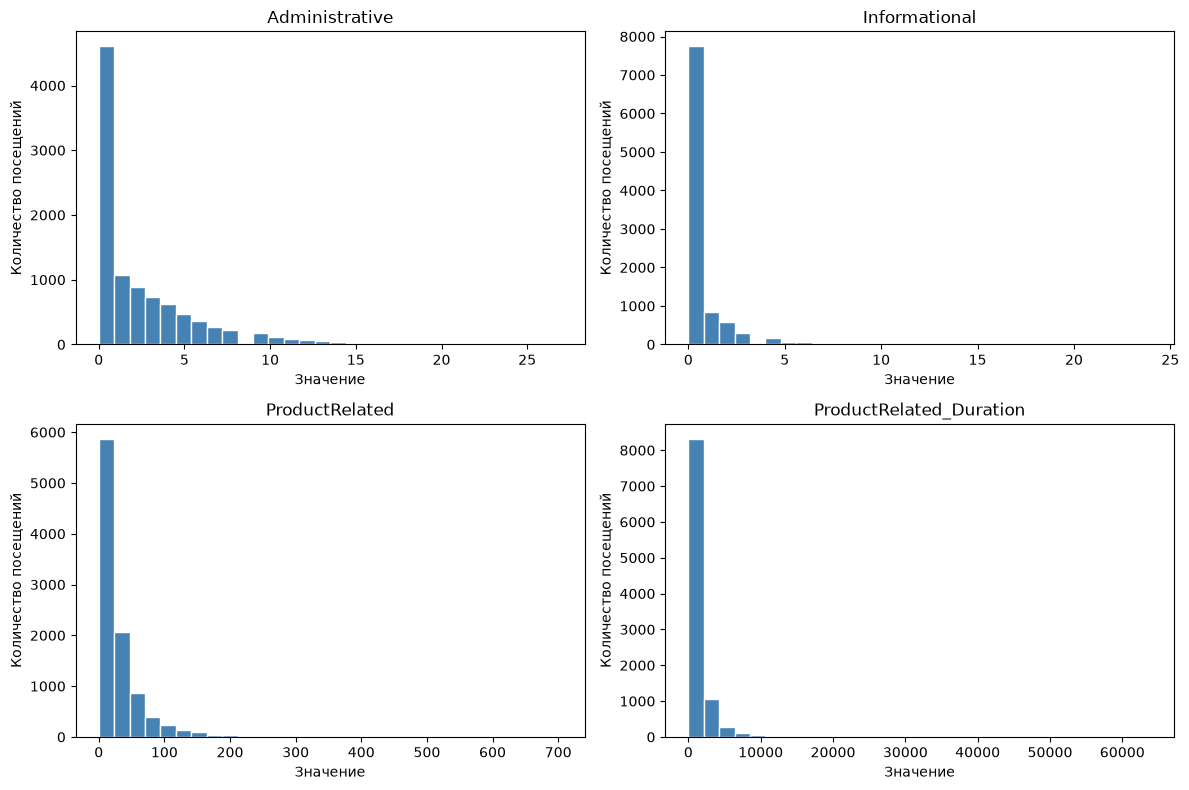

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, numeric_columns):
    ax.hist(X_train[column], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("Значение")
    ax.set_ylabel("Количество посещений")

fig.tight_layout()
plt.show()

Распределения выбранных признаков смещены вправо: большинство
значений небольшие, но встречаются значительно большие значения.

Например, медиана ProductRelated равна 18, среднее — 31,45,
а максимум — 705. Для Informational значение 75-го процентиля
равно нулю.

Большие значения растягивают шкалу графиков. Пока сохраним их:
по одному только размеру значения нельзя определить, является
ли оно ошибкой.

### Корреляции числовых признаков

Посмотрим, есть ли линейная связь между числовыми признаками.

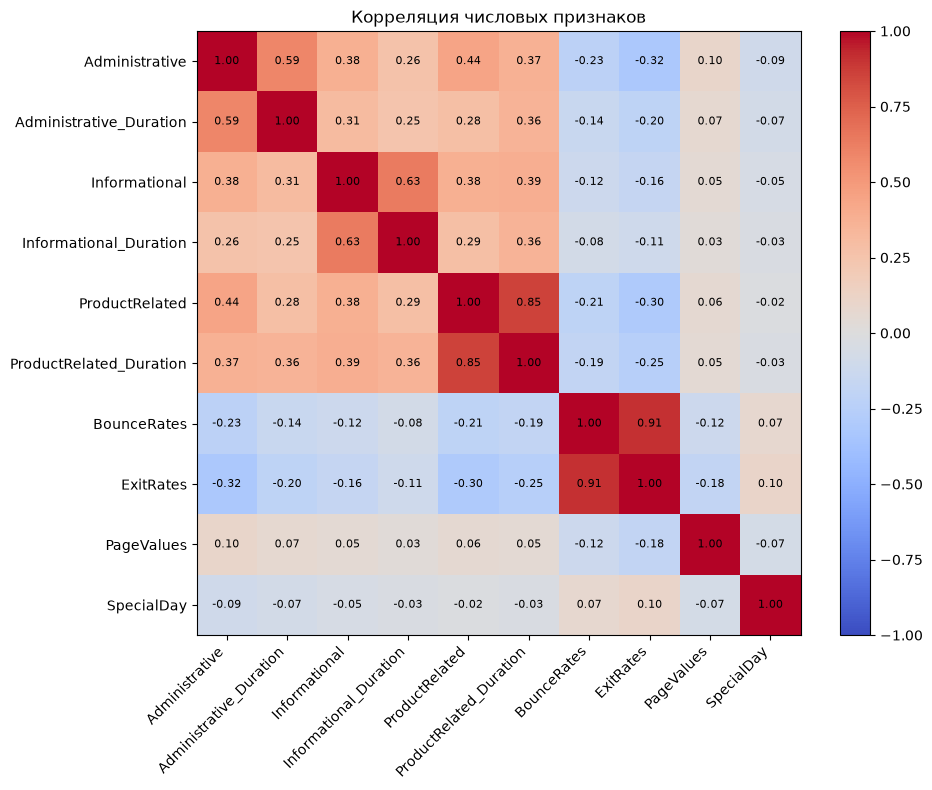

In [36]:
continuous_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]

correlation = X_train[continuous_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(continuous_columns)))
ax.set_yticks(range(len(continuous_columns)))
ax.set_xticklabels(continuous_columns, rotation=45, ha="right")
ax.set_yticklabels(continuous_columns)

for i in range(len(continuous_columns)):
    for j in range(len(continuous_columns)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8)

ax.set_title("Корреляция числовых признаков")
fig.colorbar(heatmap, ax=ax)
fig.tight_layout()
plt.show()

Самая высокая корреляция между разными признаками наблюдается
у BounceRates и ExitRates: 0,91. Также сильно связаны
ProductRelated и ProductRelated_Duration: 0,85.

Эти признаки могут содержать частично похожую информацию.
Пока оставим их и проверим влияние отбора признаков
в экспериментах с моделью.

### Признаки и покупка

Сравним количество просмотренных страниц товаров для посещений
с покупкой и без неё.

In [37]:
train_data = X_train.copy()
train_data["Revenue"] = y_train

train_data.groupby("Revenue")["ProductRelated"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,8338.0,28.55,40.31,0.0,6.0,16.0,35.0,705.0
True,1526.0,47.32,55.89,0.0,15.0,29.0,57.0,534.0


В обучающей выборке медианное количество просмотренных страниц
товаров выше для посещений с покупкой: 29 против 16 для посещений
без покупки. Таким образом, ProductRelated может быть полезным
признаком для модели, хотя сам по себе не определяет результат.

## 4. Подготовка признаков

Числовые признаки будем масштабировать, а категориальные —
кодировать с помощью One-Hot Encoding. Все преобразования
включим в Pipeline, чтобы при кросс-валидации они обучались
только на обучающей части каждого фолда.

In [38]:
categorical_columns = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
]

print("Числовые признаки:", len(continuous_columns))
print("Категориальные признаки:", len(categorical_columns))

print(
    "Неучтённые признаки:",
    set(X_train.columns) - set(continuous_columns) - set(categorical_columns),
)

Числовые признаки: 10
Категориальные признаки: 7
Неучтённые признаки: set()


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), continuous_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ]
)

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

## 5. Первая модель

Оценим логистическую регрессию с помощью стратифицированной
кросс-валидации на пяти фолдах. Основная метрика — F1 для
класса покупки. Также посмотрим на precision, recall и accuracy.

In [40]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
)

results = pd.DataFrame({
    "Метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Среднее": [
        scores["test_accuracy"].mean(),
        scores["test_precision"].mean(),
        scores["test_recall"].mean(),
        scores["test_f1"].mean(),
    ],
    "Стандартное отклонение": [
        scores["test_accuracy"].std(),
        scores["test_precision"].std(),
        scores["test_recall"].std(),
        scores["test_f1"].std(),
    ],
})

display(results.round(3))

,Метрика,Среднее,Стандартное отклонение
0,Accuracy,0.886,0.005
1,Precision,0.748,0.023
2,Recall,0.393,0.027
3,F1,0.514,0.027


Логистическая регрессия получила средний F1 0,514.
Precision составил 0,748, а recall — 0,393: модель достаточно
часто оказывается права, когда предсказывает покупку,
но находит меньше половины всех покупок.

Далее сравним её с простым базовым прогнозом и другими моделями.

In [41]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_scores = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1"],
)

print(f"Dummy accuracy: {dummy_scores['test_accuracy'].mean():.3f}")
print(f"Dummy F1:       {dummy_scores['test_f1'].mean():.3f}")

Dummy accuracy: 0.845
Dummy F1:       0.000


DummyClassifier всегда предсказывает наиболее частый класс —
отсутствие покупки. Его accuracy составляет 0,845, но F1
для класса покупки равен 0.

Логистическая регрессия получила F1 0,514 и, в отличие от
базового прогноза, обнаруживает часть покупок.

### Сравнение моделей

Сравним логистическую регрессию, дерево решений и случайный лес.
Для честного сравнения используем одинаковые фолды и метрики.

In [42]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]
)

forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
}

comparison = []

for name, model in models.items():
    model_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"],
    )

    comparison.append({
        "Модель": name,
        "Accuracy": model_scores["test_accuracy"].mean(),
        "Precision": model_scores["test_precision"].mean(),
        "Recall": model_scores["test_recall"].mean(),
        "F1": model_scores["test_f1"].mean(),
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(3))

,Модель,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.886,0.748,0.393,0.514
1,Decision Tree,0.866,0.569,0.560,0.564
2,Random Forest,0.902,0.773,0.522,0.623


Random Forest показал лучший средний F1 — 0,623.
Логистическая регрессия получила F1 0,514, поэтому первая
гипотеза предварительно подтвердилась.

Decision Tree показало самый высокий recall — 0,560, но его
precision ниже, чем у остальных моделей. Результаты получены
на кросс-валидации с исходными настройками моделей.

## 6. Проверка гипотез

### Гипотеза 2. Масштабирование

Масштабирование числовых признаков повысит F1 логистической
регрессии. Сравним модели с масштабированием и без него
на одинаковых фолдах.

In [43]:
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", continuous_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ]
)

logistic_unscaled = Pipeline(
    steps=[
        ("preprocessor", preprocessor_unscaled),
        ("classifier", LogisticRegression(max_iter=20000)),
    ]
)

scaling_comparison = []

for name, model in {
    "С масштабированием": logistic_model,
    "Без масштабирования": logistic_unscaled,
}.items():
    model_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
    )

    scaling_comparison.append({
        "Вариант": name,
        "Средний F1": model_scores["test_score"].mean(),
        "Стандартное отклонение": model_scores["test_score"].std(),
    })

display(pd.DataFrame(scaling_comparison).round(3))

/home/dbayazitov/Desktop/ШАД/Анализ данных/homework_implementation/online-shoppers-analysis/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 12585 iteration(s) (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/dbayazitov/Desktop/ШАД/Анализ данных/homework_implementation/online-shoppers-analysis/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 12571 iteration(s) (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/prepr

,Вариант,Средний F1,Стандартное отклонение
0,С масштабированием,0.514,0.027
1,Без масштабирования,0.502,0.023


При лимите 3000 итераций средний F1 составил 0,514
с масштабированием и 0,503 без него.

Модель без масштабирования не сошлась: оптимизатор достиг
лимита итераций. При увеличении max_iter до 20000 предупреждение
сохранилось, но уже из-за лимита вычислений функции и градиента;
F1 составил 0,502.

Поэтому результат сравнения предварительный: при этих настройках
масштабированная модель получила более высокий F1, но надёжно
оценить влияние масштабирования по этому эксперименту нельзя.

### Гипотеза 3. Учёт дисбаланса классов

Проверим, повысит ли class_weight="balanced" recall класса
покупки по сравнению с моделью без весов.

In [44]:
logistic_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
            ),
        ),
    ]
)

weight_comparison = []

for name, model in {
    "Без весов": logistic_model,
    "С balanced": logistic_balanced,
}.items():
    model_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["precision", "recall", "f1"],
    )

    weight_comparison.append({
        "Вариант": name,
        "Precision": model_scores["test_precision"].mean(),
        "Recall": model_scores["test_recall"].mean(),
        "F1": model_scores["test_f1"].mean(),
    })

display(pd.DataFrame(weight_comparison).round(3))

,Вариант,Precision,Recall,F1
0,Без весов,0.748,0.393,0.514
1,С balanced,0.517,0.765,0.617


Гипотеза подтвердилась: class_weight="balanced" повысил
recall с 0,393 до 0,765. При этом precision снизился
с 0,748 до 0,517, а F1 вырос с 0,514 до 0,617.

### Гипотеза 4. Глубина дерева и переобучение

Сравним дерево без ограничения глубины и дерево с max_depth=5.
Для каждого варианта посмотрим на F1 при обучении и проверке.

In [45]:
tree_depth_comparison = []

for name, depth in {
    "Без ограничения": None,
    "Глубина 5": 5,
}.items():
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

    model_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        return_train_score=True,
    )

    train_f1 = model_scores["train_score"].mean()
    validation_f1 = model_scores["test_score"].mean()

    tree_depth_comparison.append({
        "Дерево": name,
        "F1 обучение": train_f1,
        "F1 проверка": validation_f1,
        "Разрыв": train_f1 - validation_f1,
    })

display(pd.DataFrame(tree_depth_comparison).round(3))

,Дерево,F1 обучение,F1 проверка,Разрыв
0,Без ограничения,1.000,0.564,0.436
1,Глубина 5,0.691,0.644,0.047


Дерево без ограничения получило F1 1,000 на обучении и 0,564
на проверке, что указывает на переобучение. Дерево глубиной 5
показало более высокий проверочный F1 — 0,644.
Гипотеза подтвердилась: разрыв между обучающим и проверочным F1
у дерева без ограничения глубины составил 0,436, а у дерева
глубиной 5 — 0,047.

### Гипотеза 5. Отбор признаков

Проверим, снизится ли F1 логистической регрессии не более
чем на 0,02 после отбора половины признаков с помощью
SelectPercentile и f_classif.

In [46]:
from sklearn.feature_selection import SelectPercentile, f_classif

logistic_selected = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("selector", SelectPercentile(score_func=f_classif, percentile=50)),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

feature_comparison = []

for name, model in {
    "Все признаки": logistic_model,
    "Половина признаков": logistic_selected,
}.items():
    model_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
    )

    feature_comparison.append({
        "Вариант": name,
        "Средний F1": model_scores["test_score"].mean(),
        "Стандартное отклонение": model_scores["test_score"].std(),
    })

display(pd.DataFrame(feature_comparison).round(3))

,Вариант,Средний F1,Стандартное отклонение
0,Все признаки,0.514,0.027
1,Половина признаков,0.517,0.025


Гипотеза подтвердилась: после отбора половины признаков
средний F1 не снизился, а изменился с 0,514 до 0,517.

Разница небольшая, поэтому нельзя уверенно утверждать,
что отбор улучшил модель. В этом эксперименте он позволил
сократить число признаков без заметной потери качества.

### Гипотеза 6. Порог классификации

Подберём порог для логистической регрессии по F1 и сравним его
со стандартным порогом 0,5. Подбор выполняется внутри
обучающей части каждого внешнего фолда.

In [47]:
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_predict

thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for fold_number, (train_idx, validation_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    X_fold_validation = X_train.iloc[validation_idx]
    y_fold_validation = y_train.iloc[validation_idx]

    # Подбираем порог только на обучающей части внешнего фолда.
    inner_probabilities = cross_val_predict(
        logistic_model,
        X_fold_train,
        y_fold_train,
        cv=cv,
        method="predict_proba",
    )[:, 1]

    inner_scores = [
        f1_score(y_fold_train, inner_probabilities >= threshold)
        for threshold in thresholds
    ]

    best_threshold = thresholds[np.argmax(inner_scores)]

    # Обучаем модель на всей обучающей части внешнего фолда.
    model = clone(logistic_model)
    model.fit(X_fold_train, y_fold_train)

    validation_probabilities = model.predict_proba(X_fold_validation)[:, 1]

    threshold_results.append({
        "Фолд": fold_number,
        "Порог": best_threshold,
        "F1 при 0.5": f1_score(
            y_fold_validation, validation_probabilities >= 0.5
        ),
        "F1 с подбором": f1_score(
            y_fold_validation, validation_probabilities >= best_threshold
        ),
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

print("Средний F1 при пороге 0.5:", round(threshold_df["F1 при 0.5"].mean(), 3))
print("Средний F1 с подбором:", round(threshold_df["F1 с подбором"].mean(), 3))

,Фолд,Порог,F1 при 0.5,F1 с подбором
0,1,0.25,0.516,0.604
1,2,0.25,0.479,0.604
2,3,0.25,0.490,0.588
3,4,0.25,0.538,0.647
4,5,0.25,0.549,0.649


Средний F1 при пороге 0.5: 0.514
Средний F1 с подбором: 0.618


Гипотеза подтвердилась: при стандартном пороге средний F1
составил 0,514, а после подбора порога — 0,618.

В каждом внешнем фолде был выбран порог 0,25. Порог подбирался
на обучающей части фолда и оценивался на отдельной проверочной
части, поэтому результат не получен на тех же данных,
по которым выбирался порог.

## 7. Подбор гиперпараметров

Подберём параметры дерева решений с помощью GridSearchCV.
Основная метрика при выборе — F1 класса покупки.

In [48]:
from sklearn.model_selection import GridSearchCV

tree_parameters = {
    "classifier__max_depth": [3, 5, 7, 10],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
}

tree_search = GridSearchCV(
    estimator=tree_model,
    param_grid=tree_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

tree_search.fit(X_train, y_train)

print("Лучшие параметры:", tree_search.best_params_)
print("Средний F1 при кросс-валидации:", round(tree_search.best_score_, 3))

Лучшие параметры: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 20}
Средний F1 при кросс-валидации: 0.646


GridSearchCV выбрал дерево с max_depth=5 и
min_samples_leaf=20. Средний F1 лучшей комбинации
при кросс-валидации составил 0,646.

Эта оценка получена на фолдах, использованных для выбора
параметров. Итоговое качество проверим на тестовой выборке.

### Проверка влияния PageValues

PageValues связан со стоимостью страниц перед транзакцией.
Проверим, как изменится качество дерева без этого признака.
Доступность PageValues до покупки по описанию данных неясна,
поэтому результат нужно интерпретировать с осторожностью.

In [49]:
numeric_without_pagevalues = [
    column for column in continuous_columns
    if column != "PageValues"
]

preprocessor_without_pagevalues = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_without_pagevalues),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ]
)

tree_with_pagevalues = clone(tree_search.best_estimator_)

tree_without_pagevalues = clone(tree_search.best_estimator_)
tree_without_pagevalues.set_params(
    preprocessor=preprocessor_without_pagevalues
)

pagevalues_comparison = []

for name, model in {
    "С PageValues": tree_with_pagevalues,
    "Без PageValues": tree_without_pagevalues,
}.items():
    model_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["precision", "recall", "f1"],
    )

    pagevalues_comparison.append({
        "Вариант": name,
        "Precision": model_scores["test_precision"].mean(),
        "Recall": model_scores["test_recall"].mean(),
        "F1": model_scores["test_f1"].mean(),
    })

display(pd.DataFrame(pagevalues_comparison).round(3))

,Вариант,Precision,Recall,F1
0,С PageValues,0.708,0.596,0.646
1,Без PageValues,0.463,0.096,0.157


При удалении PageValues средний F1 дерева снизился с 0,646
до 0,157, а recall — с 0,596 до 0,096. При выбранных параметрах
модель сильно зависит от этого признака.

По описанию данных нельзя однозначно установить, как PageValues
был рассчитан и доступен ли он до покупки. Поэтому результаты
с этим признаком следует интерпретировать с осторожностью.
Параметры дерева подбирались с PageValues, поэтому сравнение
с моделью без него является предварительным.

## 8. Итоговая оценка на тестовой выборке

Оценим выбранное дерево с PageValues и проведём дополнительную
проверку без этого признака. Параметры зафиксированы до просмотра
результатов на тестовой выборке.

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

test_results = []

for name, model in {
    "С PageValues": tree_with_pagevalues,
    "Без PageValues": tree_without_pagevalues,
}.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    test_results.append({
        "Вариант": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
    })

    print(f"\n{name}: матрица ошибок")
    print(confusion_matrix(y_test, predictions))

display(pd.DataFrame(test_results).round(3))


С PageValues: матрица ошибок
[[1992   92]
 [ 156  226]]

Без PageValues: матрица ошибок
[[2046   38]
 [ 347   35]]


,Вариант,Accuracy,Precision,Recall,F1
0,С PageValues,0.899,0.711,0.592,0.646
1,Без PageValues,0.844,0.479,0.092,0.154


На тестовой выборке дерево с PageValues получило F1 0,646.
Модель обнаружила 226 из 382 покупок и ошибочно предсказала
покупку для 92 посещений без неё.

Без PageValues F1 снизился до 0,154, а модель обнаружила
35 покупок. Параметры дерева подбирались с PageValues, поэтому
это предварительная проверка влияния признака, а не оценка
лучшей возможной модели без него.

Доступность PageValues до покупки нужно уточнить. До этого
результат с ним нельзя считать надёжной оценкой модели для
прогноза во время сессии.

## 9. Итоговые выводы

1. Random Forest превзошёл логистическую регрессию по среднему
   F1 на кросс-валидации: 0,623 против 0,514. Гипотеза
   подтвердилась для сравниваемых настроек.

2. С масштабированием F1 составил 0,514, без него — около 0,502 при max_iter=20000.
   Модель без масштабирования не сошлась, поэтому надёжный вывод
   о влиянии масштабирования сделать нельзя.

3. class_weight="balanced" повысил recall логистической регрессии
   с 0,393 до 0,765, но снизил precision. Гипотеза подтвердилась.

4. Дерево без ограничения глубины имело больший разрыв между F1
   на обучении и проверке, чем дерево глубиной 5. Гипотеза
   подтвердилась.

5. После отбора половины признаков F1 изменился с 0,514 до 0,517.
   Допустимого снижения не произошло, поэтому гипотеза
   подтвердилась в данном эксперименте.

6. Подбор порога повысил средний F1 с 0,514 до 0,618 во вложенной
   кросс-валидации. Гипотеза подтвердилась.

Выбранное дерево с PageValues получило F1 0,646 на тестовой
выборке. Результат сильно зависит от PageValues, а доступность
этого признака до покупки требует уточнения.